In [1]:
import torch
import timm
import torch.nn.functional as F
from torchvision.transforms.functional import gaussian_blur
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

/Users/kim.bente/Code/RadarCLIP/ml_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from paths import path_to_tiles_tensor
from paths import path_to_labels_tensor
from paths import path_to_tiles_tensor_3C

In [3]:
tiles = torch.load(path_to_tiles_tensor)
labels = torch.load(path_to_labels_tensor)
# extract batch
batch = tiles[0:10, :, :, :]

## First channel: Normalise only (same across)

In [4]:
batch_size = 50
q = torch.tensor([0.05, 0.95])

low_quantile_per_tile = []
high_quantile_per_tile = []

for i in range(0, tiles.shape[0], batch_size):
    analysis_batch = tiles[i:i + batch_size]                   
    flat = analysis_batch.reshape(analysis_batch.shape[0], analysis_batch.shape[1], -1).float()
    qs = torch.quantile(flat, q, dim = -1)         
    low_quantile_per_tile.append(qs[0])              
    high_quantile_per_tile.append(qs[1])

low_quantile_per_tile = torch.cat(low_quantile_per_tile)
high_quantile_per_tile = torch.cat(high_quantile_per_tile)

lower_absolute = torch.min(low_quantile_per_tile)
upper_absolute = torch.max(high_quantile_per_tile)

print(lower_absolute.item())
print(upper_absolute.item())

90.87999725341797
200.5922393798828


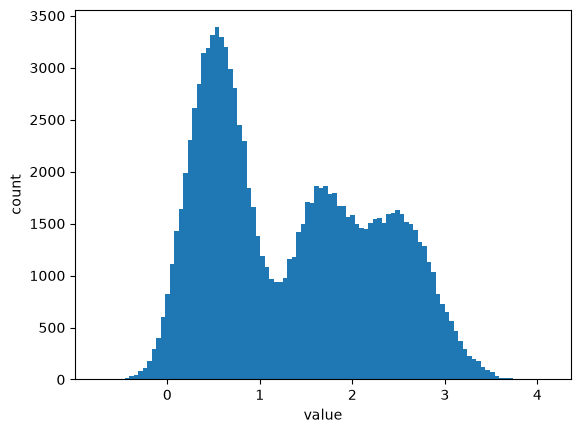

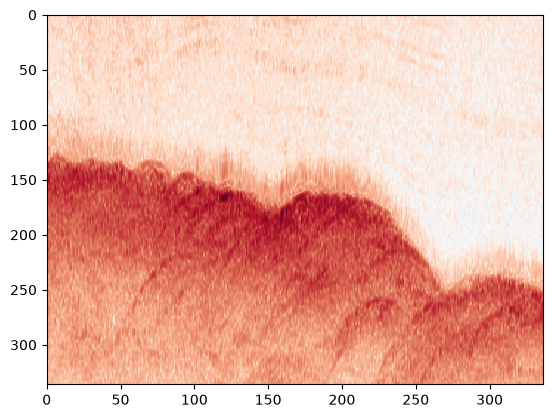

In [5]:
def normalise(batch_of_tiles, low = 100.0, high = 180.00):
    ### Normalise all tiles with same values to retain absolute meaning
    # e.g. 145 becomes 0 (center)
    center = (low + high) / 2
    # e.g. 90 becomes -3 and 200 becomes 3      
    half_range = (high - low) / 2 

    batch_of_tiles_norm = (batch_of_tiles - center) / half_range * 3

    return batch_of_tiles_norm

batch_of_tiles_norm = normalise(batch)

# Look at distribution
i = 7
x = batch_of_tiles_norm[i].flatten().detach().cpu().numpy()
plt.hist(x, bins = 100)
plt.xlabel("value")
plt.ylabel("count")
plt.show()

plt.pcolormesh(batch_of_tiles_norm[i, 0], cmap = "RdBu_r", vmin = -4, vmax = 4)
plt.gca().invert_yaxis()
plt.show()

## Second channel: Normalise against attenuation proxy

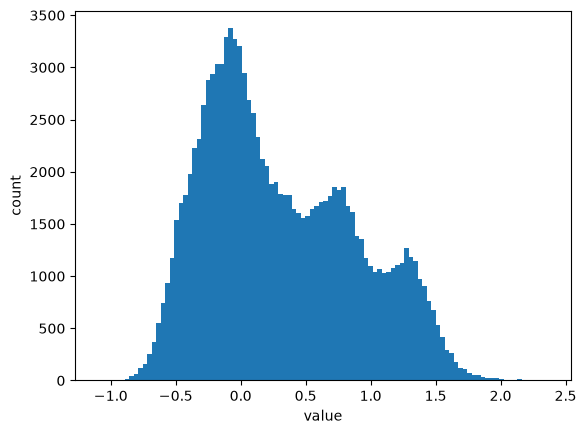

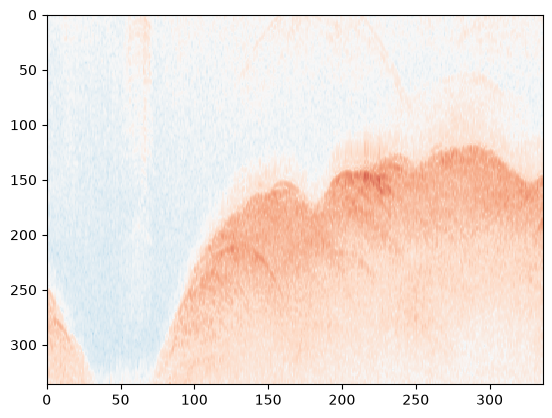

In [6]:
def normalise_wrt_near_basal_power(batch_of_tiles, window_width = 40, full_window_height = 100, scalar = 0.05):
    ### This function expresses echo relative to the mean near basal ice echo (proxy for attenuation correction)
    # input shape: (N, 1, H, W)
    # output shape: (N, 1, H, W)
    H = batch_of_tiles.shape[-2]
    W = batch_of_tiles.shape[-1]
    half_W = int(W / 2)
    half_window_width = int(window_width / 2)
    # mean over C1 , H and W but keepdim for subtraction
    batch_near_basal_mean = batch_of_tiles[:, :, :full_window_height, (half_W - half_window_width) : (half_W + half_window_width)].mean(dim = (1, 2, 3), keepdim = True)

    # subtract this to make it 0
    batch_of_tiles_shifted = batch_of_tiles - batch_near_basal_mean

    # scalar (fixed)
    batch_of_tiles_shifted_scaled = batch_of_tiles_shifted * scalar

    return batch_of_tiles_shifted_scaled

batch_of_tiles_shifted_scaled = normalise_wrt_near_basal_power(batch)

# Look at distribution
i = 2
x = batch_of_tiles_shifted_scaled[i].flatten().detach().cpu().numpy()
plt.hist(x, bins = 100)
plt.xlabel("value")
plt.ylabel("count")
plt.show()

plt.pcolormesh(batch_of_tiles_shifted_scaled[i, 0], cmap = "RdBu_r", vmin = -4, vmax = 4)
plt.gca().invert_yaxis()
plt.show()

## Third channel: Extract contours

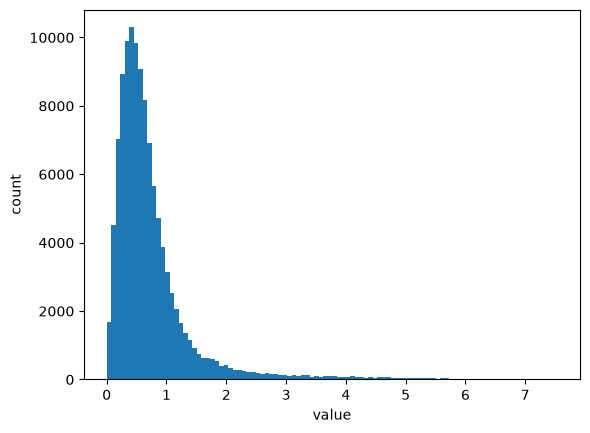

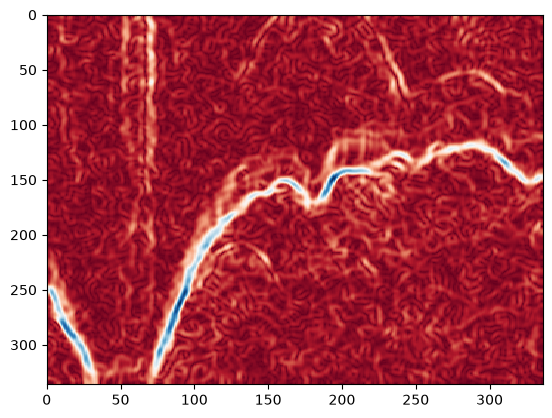

In [7]:
_KX = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])

def apply_sobel(batch_of_tiles, scalar = 0.2):
    # input shape: (N, 1, H, W)
    # output shape: (N, 1, H, W)
    # first smooth out noise and speckle
    batch_of_tiles_smoothed = gaussian_blur(batch_of_tiles, kernel_size = 9, sigma = 2.0)
    # horizontal and vertical sobel 3 x 3 kernel i.e. window to detect horizontal and vertical change
    # kernels: torch.Size([2, 1, 3, 3])
    kernels = torch.stack([_KX, _KX.T])[:, None].to(batch_of_tiles.device, batch_of_tiles.dtype)   
    # borders             
    g = F.conv2d(F.pad(batch_of_tiles_smoothed, (1, 1, 1, 1), mode = 'reflect'), kernels)
    # collapeses both sobels into one and keep only positive values.
    g = g.norm(dim = 1, keepdim = True) 
    # scale to reduce std
    g = g * scalar
    return g

g = apply_sobel(batch)

i = 2
x = g[i].flatten().detach().cpu().numpy()
plt.hist(x, bins = 100)
plt.xlabel("value")
plt.ylabel("count")
plt.show()

plt.pcolormesh(g[i, 0], cmap = "RdBu")
# plt.pcolormesh(g[i, 0], cmap = "RdBu", vmin = -3, vmax = 3)
plt.gca().invert_yaxis()
plt.show()

# Combine

In [8]:
def channelise(batch_of_tiles):
    # input shape: (N, 1, H, W)
    # output shape: (N, 3, H, W)
    batch_norm = normalise(batch_of_tiles)
    batch_norm_rel = normalise_wrt_near_basal_power(batch_of_tiles)
    batch_sobel = apply_sobel(batch_of_tiles)

    # cat along dim 1 
    batch_3C = torch.cat([batch_norm, batch_norm_rel, batch_sobel], dim = 1)
    return batch_3C

print(batch.shape)
batchy_3D = channelise(batch)
print(batchy_3D.shape)

# Need batched loop or not?
tiles_3C = channelise(tiles)
torch.save(tiles_3C, path_to_tiles_tensor_3C)

torch.Size([10, 1, 336, 336])
torch.Size([10, 3, 336, 336])


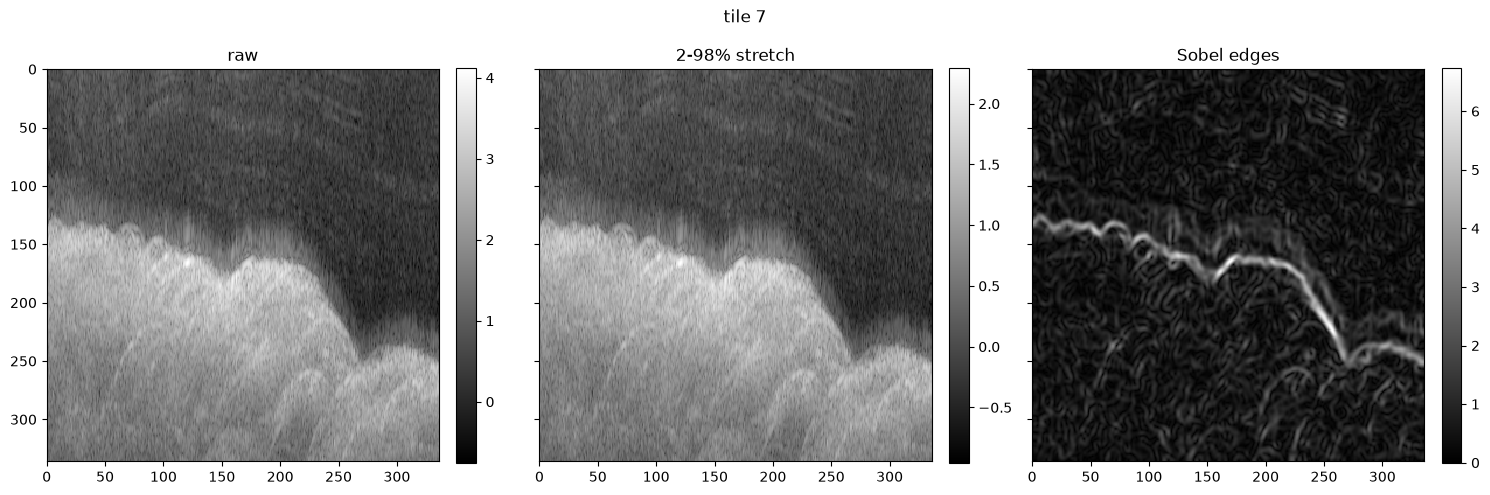

In [ ]:
def show_three(tiles_3ch, i, titles=("raw", "2-98% stretch", "Sobel edges")):
    fig, axes = plt.subplots(1, 3, figsize = (15, 5), sharex=True, sharey=True)
    for ax, ch, title in zip(axes, tiles_3ch[i].cpu(), titles):
        m = ax.pcolormesh(ch.numpy(), cmap = 'gray', shading = 'auto', )
        ax.set_title(title)
        ax.set_aspect('equal')
        fig.colorbar(m, ax = ax, fraction = 0.046, pad = 0.04)
    axes[0].invert_yaxis()  # pcolormesh puts row 0 at the bottom; flip to match imshow
    fig.suptitle(f"tile {i}")
    plt.tight_layout()
    plt.show()

show_three(tiles_3C, 7)

In [23]:
index = 7
for i in range(3):
    # (C, H, W) -> (H, W); same channel mean as in your earlier plots
    tile = tiles_3C[index, i].cpu().numpy()
    print(tile.shape)

(336, 336)
(336, 336)
(336, 336)


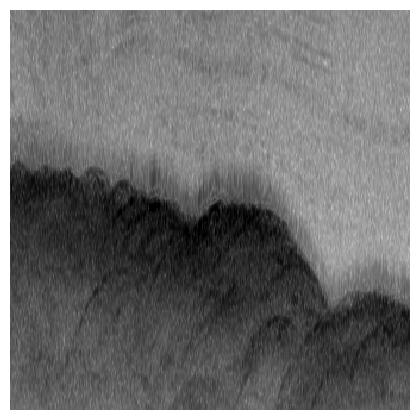

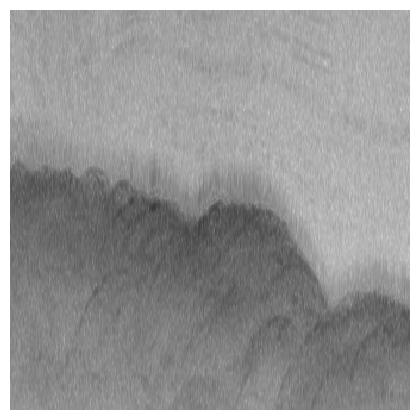

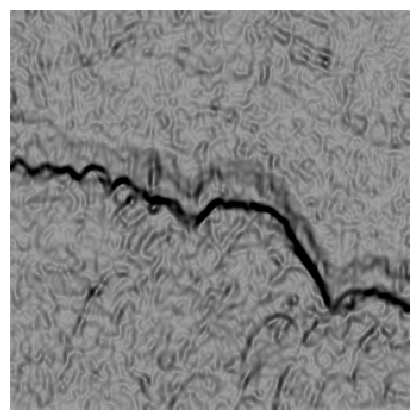

In [33]:
from preprocess_radargrams_configs import AMPLITUDE_VMIN, AMPLITUDE_VMAX, COLOR_MAP
figures_dir = "figures/EAGLE_2016_HiCARS2/channels"
import os

index = 7
for i in range(3):
    # (C, H, W) -> (H, W); same channel mean as in your earlier plots
    tile = tiles_3C[index, i].cpu().numpy()
    h, w = tile.shape

    # figure sized to the tile's aspect ratio, axes fill the whole canvas
    fig = plt.figure(figsize = (w / h * 4, 4))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.pcolormesh(tile, cmap = COLOR_MAP, vmin = -2, vmax = 3.5)
    ax.invert_yaxis()      
    ax.set_axis_off()

    fig.savefig(os.path.join(figures_dir, f"tile_{i:06d}.png"), dpi = 300, bbox_inches = "tight", pad_inches = 0)

# Train

In [9]:
import timm, torch, torch.nn as nn
# from PIL import Image
from timm.data import create_transform
from torch.utils.data import DataLoader, Dataset
 
device = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 50
BATCH_SIZE = 128
TILE_SIZE = 336
LR = 1e-4
WEIGHT_DECAY = 0.05
TEMP = 2.0

def RnC_loss(z, y, t = TEMP):
    ### Rank-n-Contrastive loss
    # z are the embeddings of shape (N, embedding_dim)
    # y are the labels
    n = len(z)
    # pair-wise similarities is defined as the negative l2 distance, scaled by temperature
    # negative makes close embeddings score high
    sim = - torch.cdist(z, z) / t
    # label distances (unsqueeze one dim) |y_i - y_j|                      
    dy = torch.cdist(y[:, None], y[:, None], p = 1) 
    # indicate self-pairs (for exclusion)
    eye = torch.eye(n, dtype = torch.bool, device = z.device)
    # 3D tensor mask
    # mask[i, j, k]: k != i and |y_i - y_k| >= |y_i - y_j|  (the set S_{i,j})
    mask = (dy[:, None, :] >= dy[:, :, None]) & ~ eye[:, None, :]
    denom = sim[:, None, :].expand(n, n, n).masked_fill(~ mask, float("-inf")).logsumexp(-1)
    # loss to minimise
    return -(sim - denom)[~ eye].mean()

class Data(Dataset):
    def __init__(self, x, y):
        # x: (N, 3, H, W) tensor
        # y: (N,) tensor
        self.x, self.y = x, y
    def __len__(self): return len(self.x)
    def __getitem__(self, i):
        return self.x[i], self.y[i]

def main(x, y):
    # create model
    model = timm.create_model(
        # load ViT-Small with 16 × 16 patches (can be extended to 336)
        "vit_small_patch16_224", 
        # start from ImageNet weights
        pretrained = True, 
        # no classification head but 384-dim embedding instead
        num_classes = 0, 
        # overwrite image size: 336 / 16 = 21
        img_size = TILE_SIZE).to(device)
    
    # retrieve processing configs
    cfg = timm.data.resolve_data_config({}, model = model)
    print(cfg)

    # define dataloader
    loader = DataLoader(
        Data(x, y.float()), 
        BATCH_SIZE, 
        shuffle = True, 
        # drop final batch if smaller than BATCH_SIZE (important for contrastive loss)
        drop_last = True, 
        # CPU to prepape 
        # 4 caused an issue
        num_workers = 0)

    # define optimiser
    opt = torch.optim.AdamW(model.parameters(), lr = LR, weight_decay = WEIGHT_DECAY)

    # define schedule
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)

    # put into training model
    model.train()

    for ep in range(EPOCHS):
        for x_batch, y_batch in loader:
            # put on device
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            # mixed precision for speed
            with torch.autocast(device, dtype = torch.bfloat16, enabled = device == "cuda"):
                # retrieve embeddings
                z = model(x_batch)
            loss = RnC_loss(z.float(), y_batch)
            opt.zero_grad(set_to_none = True); loss.backward(); opt.step()
        sched.step()
        print(f"epoch {ep}: loss {loss.item():.4f}")

    torch.save(model.state_dict(), "models/rnc_vit_s.pt")
 
if __name__ == "__main__":
    # (~ 10000, 3, 336, 336), (~ 10000,)
    main(torch.load(path_to_tiles_tensor_3C), torch.load(path_to_labels_tensor))

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'crop_pct': 0.9, 'crop_mode': 'center'}
epoch 0: loss 3.7254
epoch 1: loss 3.7145
epoch 2: loss 3.7041
epoch 3: loss 3.6153
epoch 4: loss 3.5163
epoch 5: loss 3.4744
epoch 6: loss 3.3184
epoch 7: loss 3.0571
epoch 8: loss 3.3287
epoch 9: loss 2.9018
epoch 10: loss 2.9678
epoch 11: loss 2.9373
epoch 12: loss 2.7619
epoch 13: loss 2.7484
epoch 14: loss 2.6206
epoch 15: loss 2.5310
epoch 16: loss 2.6049
epoch 17: loss 2.4578
epoch 18: loss 2.3527
epoch 19: loss 2.3670
epoch 20: loss 2.4541
epoch 21: loss 2.3048
epoch 22: loss 2.1451
epoch 23: loss 2.0601
epoch 24: loss 2.0469
epoch 25: loss 2.1037
epoch 26: loss 2.0138
epoch 27: loss 1.9617
epoch 28: loss 1.9505
epoch 29: loss 1.9150
epoch 30: loss 1.8200
epoch 31: loss 1.9895
epoch 32: loss 1.8271
epoch 33: loss 1.7308
epoch 34: loss 1.5935
epoch 35: loss 1.5454
epoch 36: loss 1.4770
epoch 37: loss 1.3262
epoch 38: loss 1.2780
epoch

# Train for 20 more epochs

In [14]:
EXTRA_EPOCHS = 20

# load model
model = timm.create_model(
    "vit_small_patch16_224",
    pretrained = False,        # weights come from your checkpoint, no need to download ImageNet
    num_classes = 0,
    img_size = TILE_SIZE).to(device)

# load weights
model.load_state_dict(torch.load("models/rnc_vit_s_50_epochs.pt", map_location = device))

# cfg = timm.data.resolve_data_config({}, model = model)

x = torch.load(path_to_tiles_tensor_3C)
y = torch.load(path_to_labels_tensor)

# define dataloader
loader = DataLoader(
    Data(x, y.float()), 
    BATCH_SIZE, 
    shuffle = True, 
    # drop final batch if smaller than BATCH_SIZE (important for contrastive loss)
    drop_last = True, 
    # CPU to prepape 
    # 4 caused an issue
    num_workers = 0)

# define optimiser
opt = torch.optim.AdamW(model.parameters(), lr = LR, weight_decay = WEIGHT_DECAY)

# define schedule
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)

model.train()

for ep in range(EXTRA_EPOCHS):
    for x_batch, y_batch in loader:
        # put on device
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        # mixed precision for speed
        with torch.autocast(device, dtype = torch.bfloat16, enabled = device == "cuda"):
            # retrieve embeddings
            z = model(x_batch)
        loss = RnC_loss(z.float(), y_batch)
        opt.zero_grad(set_to_none = True); loss.backward(); opt.step()
    sched.step()
    print(f"epoch {ep}: loss {loss.item():.4f}")

torch.save(model.state_dict(), "models/rnc_vit_s_70_epochs.pt")

epoch 0: loss 1.8589
epoch 1: loss 2.0052
epoch 2: loss 1.8784
epoch 3: loss 2.1307
epoch 4: loss 2.2291
epoch 5: loss 2.4091
epoch 6: loss 2.1935
epoch 7: loss 2.0955
epoch 8: loss 2.2536
epoch 9: loss 2.0439
epoch 10: loss 2.0856
epoch 11: loss 2.2926
epoch 12: loss 2.1045
epoch 13: loss 2.0750
epoch 14: loss 1.9141


KeyboardInterrupt: 